In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
#df = pd.read_csv('AbsTimes_Intzones_merged.csv')
df = pd.read_csv('AbsTimes_Intzones_DREADDs_SFC_merged_v3_test.csv')

df = df.drop('Cups Hab', 1)

data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))

In [3]:
#df = pd.read_csv('AbsTimes_RatioHalves_merged.csv')
df = pd.read_csv('AbsTimesHalves_DREADDs_merged_SFC_v3.csv')


df = df.drop('Cups Hab', 1)

data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf_h = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))

In [4]:
newdf_h = newdf_h.replace({'y': "y halves", "n": "n halves"})
newdf = pd.concat([newdf_h,newdf])
newdf

,Experimental Condition,Left preference,control
0,Cups LTM,154.900000,y halves
1,Cups LTM,123.000000,y halves
2,Cups LTM,270.870000,n halves
3,Cups LTM,241.400000,y halves
4,Cups LTM,211.500000,y halves
...,...,...,...
79,LTM,22.750000,n
80,LTM,4.552846,n
81,LTM,29.600000,n
82,LTM,25.849761,n


In [5]:
def map_half(i,num):
    if(i%4 < 2):
        return 0
    return 1

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript back

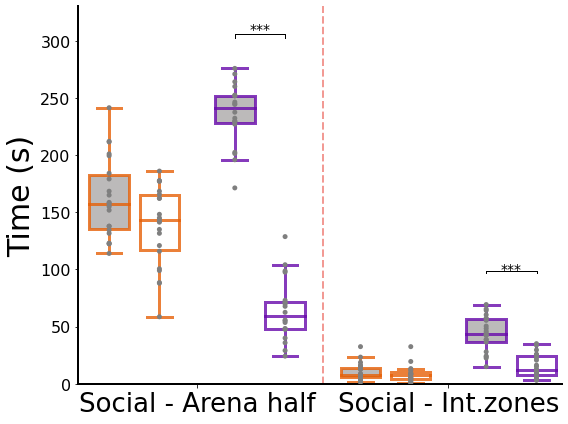

In [17]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}


text_boxplot = ['','***','****']
colors = ["C7","C7"]
colors_boxplot = ['#e66007', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    #order = ['n halves','y halves'],
    x='control',
    palette=colors,
    jitter=0,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    #order = ['n halves','y halves'],
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=3,
    
    **PROPS
)

# plt.axhline(linewidth=2, color='grey',ls='--')
plt.axvline(linewidth=2, x=1.5, color='#f29a94',ls='--')


data_ratio = 0.4016222222466667


# #CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    facecolor = '#aba9a9' if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
# #END CHANGE BOXPLOT STYLE

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)
plt.legend([],[], frameon=False)

ax.set_xticks([0.5,2.5])
ax.set_xticklabels(['Social - Arena half','Social - Int.zones'], fontsize = 26)

ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


# ax.text(-0.38,325.15,'Upper half', fontsize = 20)
# ax.text(0.71,325.15,'CS- half', fontsize = 20)

# ax.text(1.58,325.15,'Upper zone', fontsize = 20)
# ax.text(2.68,325.15,'CS- zone', fontsize = 20)

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Time (s)', fontsize = 30)

ax.set_ylim([0,330])
ax.set_xlim([-0.45,3.4])


significance(ax,1,data_ratio,310,text=text_boxplot[1],offset=-4,whisker=4)
significance(ax,3,data_ratio,100,text=text_boxplot[1],offset=-1,whisker=2)

#plt.title("Side preference arena", fontsize=24,y=1.1)

fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(8,6)
ax.tick_params(axis='y', which='major', labelsize=16)

plt.tight_layout()
fig.tight_layout()
fig.savefig("AbsTimesIntzones_Halves_merged_DREADDs.jpg",dpi=500,bbox_inches='tight')
plt.savefig('AbsTimesIntzones_Halves_merged_DREADDs.eps', format='eps')